In [24]:
import os, warnings
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
os.makedirs("charts", exist_ok=True)
def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150)
    plt.show()

In [25]:
df = pd.read_csv("cleaned_data.csv")
df["Transaction Date"] = pd.to_datetime(df["Transaction Date"], errors="coerce")
df["Month"] = df["Transaction Date"].dt.to_period("M").astype(str)
df["Weekday"] = df["Transaction Date"].dt.day_name()
df["Is Weekend"] = df["Transaction Date"].dt.dayofweek >= 5
print("Shape:", df.shape)
print("Date range:", df["Transaction Date"].min().date(), "to", df["Transaction Date"].max().date())
print("Missing values:\n", df.isna().sum())
print("Duplicate transaction IDs:", df["Transaction ID"].duplicated().sum())
df.head()

Shape: (9501, 11)
Date range: 2023-01-01 to 2023-12-31
Missing values:
 Transaction ID       0
Item                 0
Quantity             0
Price Per Unit      16
Total Spent          0
Payment Method       0
Location             0
Transaction Date     0
Month                0
Weekday              0
Is Weekend           0
dtype: int64
Duplicate transaction IDs: 0


,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date,Month,Weekday,Is Weekend
0,Txn_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08,2023-09,Friday,False
1,Txn_4977031,Cake,4,3.0,12.0,Cash,In-Store,2023-05-16,2023-05,Tuesday,False
2,Txn_4271903,Cookie,4,1.0,4.0,Credit Card,In-Store,2023-07-19,2023-07,Wednesday,False
3,Txn_7034554,Salad,2,5.0,10.0,Unknown,Unknown,2023-04-27,2023-04,Thursday,False
4,Txn_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-Store,2023-06-11,2023-06,Sunday,True


In [19]:
num_cols = ["Quantity", "Price Per Unit", "Total Spent"]
stats = df[num_cols].describe().T
stats["median"] = df[num_cols].median()
stats["skew"] = df[num_cols].skew()
stats.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew
Quantity,9501.0,3.02,1.42,0.0,2.0,3.0,4.0,5.0,3.0,-0.01
Price Per Unit,9485.0,2.95,1.28,1.0,2.0,3.0,4.0,5.0,3.0,0.01
Total Spent,9501.0,8.92,6.01,1.0,4.0,8.0,12.0,25.0,8.0,0.83


In [20]:
for col in ["Item", "Payment Method", "Location"]:
    print(f"--- {col} ---")
    print(df[col].value_counts().to_frame("count").assign(share=lambda x: (x["count"] / len(df) * 100).round(1)))
    print()

--- Item ---
          count  share
Item                  
Coffee     1159   12.2
Salad      1132   11.9
Juice      1120   11.8
Cake       1080   11.4
Cookie     1068   11.2
Sandwich   1067   11.2
Tea        1058   11.1
Smoothie   1044   11.0
Unknown     491    5.2
Error       282    3.0

--- Payment Method ---
                count  share
Payment Method              
Unknown          2708   28.5
Digital Wallet   2188   23.0
Credit Card      2163   22.8
Cash             2148   22.6
Error             294    3.1

--- Location ---
          count  share
Location              
Unknown    3428   36.1
Takeaway   2876   30.3
In-Store   2858   30.1
Error       339    3.6



In [21]:
print(f"Total revenue:        {df['Total Spent'].sum():,.0f}")
print(f"Total transactions:   {len(df):,}")
print(f"Average order value:  {df['Total Spent'].mean():.2f}")
print(f"Median order value:   {df['Total Spent'].median():.2f}")
print(f"Total units sold:     {df['Quantity'].sum():,}")

Total revenue:        84,786
Total transactions:   9,501
Average order value:  8.92
Median order value:   8.00
Total units sold:     28,664


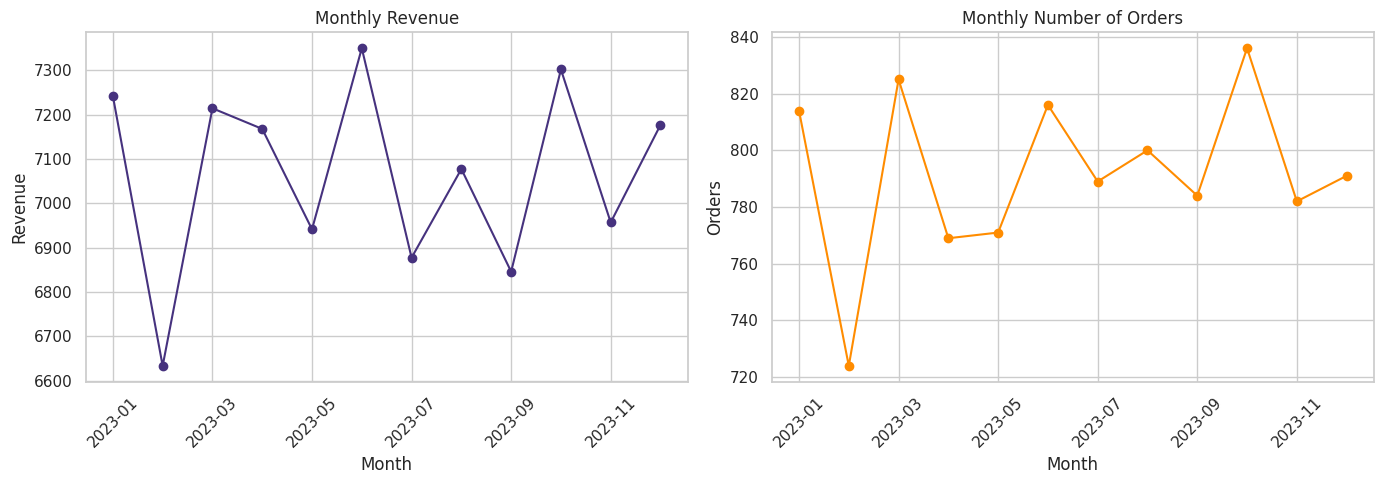

,Revenue,Orders
Month,,
2023-01,7242.0,814
2023-02,6634.0,724
2023-03,7214.0,825
2023-04,7168.0,769
2023-05,6942.0,771
2023-06,7350.0,816
2023-07,6878.0,789
2023-08,7078.0,800
2023-09,6846.0,784


In [26]:
monthly = df.groupby("Month").agg(Revenue=("Total Spent", "sum"), Orders=("Transaction ID", "count"))
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
monthly["Revenue"].plot(marker="o", ax=ax[0], title="Monthly Revenue")
ax[0].set_ylabel("Revenue"); ax[0].tick_params(axis="x", rotation=45)
monthly["Orders"].plot(marker="o", color="darkorange", ax=ax[1], title="Monthly Number of Orders")
ax[1].set_ylabel("Orders"); ax[1].tick_params(axis="x", rotation=45)
save("01_monthly_trend")
monthly.round(0)

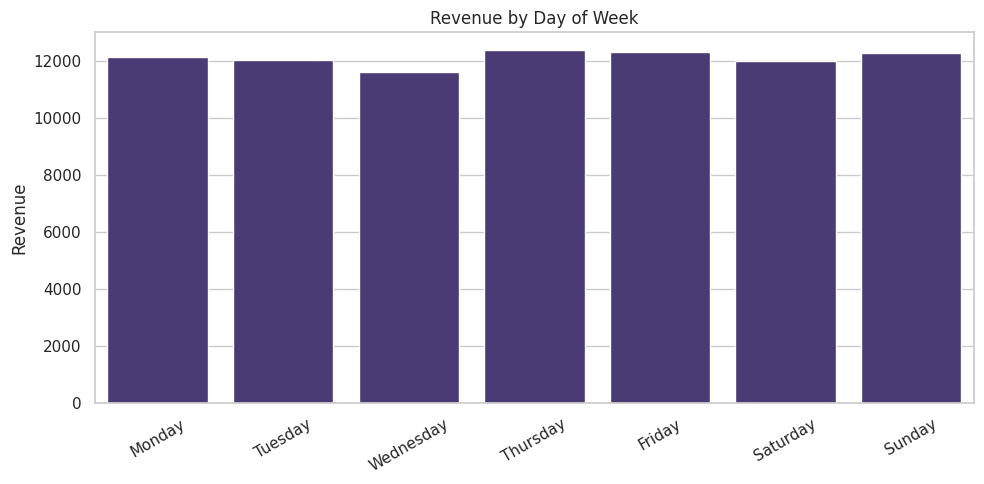

In [27]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = df.groupby("Weekday")["Total Spent"].sum().reindex(order)
sns.barplot(x=weekday.index, y=weekday.values)
plt.title("Revenue by Day of Week"); plt.ylabel("Revenue"); plt.xlabel("")
plt.xticks(rotation=30)
save("02_weekday_revenue")

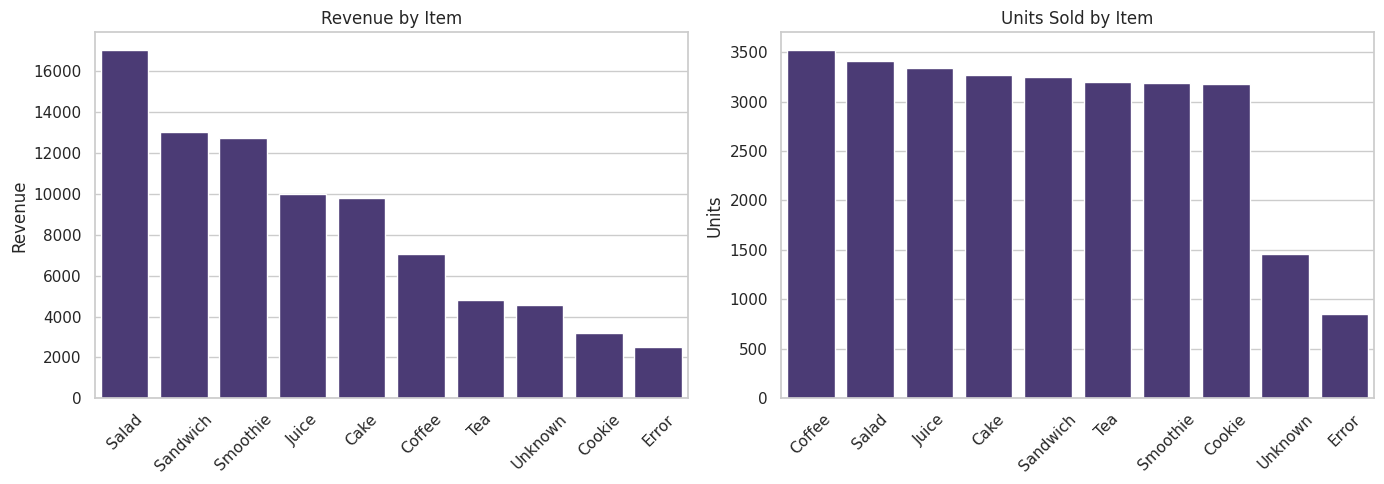

,Revenue,Units,Orders,Price,Revenue Share %
Item,,,,,
Salad,17060.0,3411,1132,5.00,20.1
Sandwich,13016.0,3249,1067,4.00,15.4
Smoothie,12760.0,3184,1044,4.00,15.0
Juice,10017.0,3339,1120,3.00,11.8
Cake,9825.0,3269,1080,3.00,11.6
Coffee,7050.0,3523,1159,2.00,8.3
Tea,4812.0,3197,1058,1.50,5.7
Unknown,4576.5,1461,491,3.10,5.4
Cookie,3177.0,3175,1068,1.00,3.7


In [9]:
item_stats = (df.groupby("Item")
                .agg(Revenue=("Total Spent", "sum"), Units=("Quantity", "sum"),
                     Orders=("Transaction ID", "count"), Price=("Price Per Unit", "mean"))
                .sort_values("Revenue", ascending=False))
item_stats["Revenue Share %"] = (item_stats["Revenue"] / item_stats["Revenue"].sum() * 100).round(1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=item_stats.index, y=item_stats["Revenue"], ax=ax[0])
ax[0].set_title("Revenue by Item"); ax[0].tick_params(axis="x", rotation=45); ax[0].set_xlabel("")
sns.barplot(x=item_stats.index, y=item_stats["Units"], ax=ax[1],
            order=item_stats.sort_values("Units", ascending=False).index)
ax[1].set_title("Units Sold by Item"); ax[1].tick_params(axis="x", rotation=45); ax[1].set_xlabel("")
save("03_item_revenue_units")
item_stats.round(2)

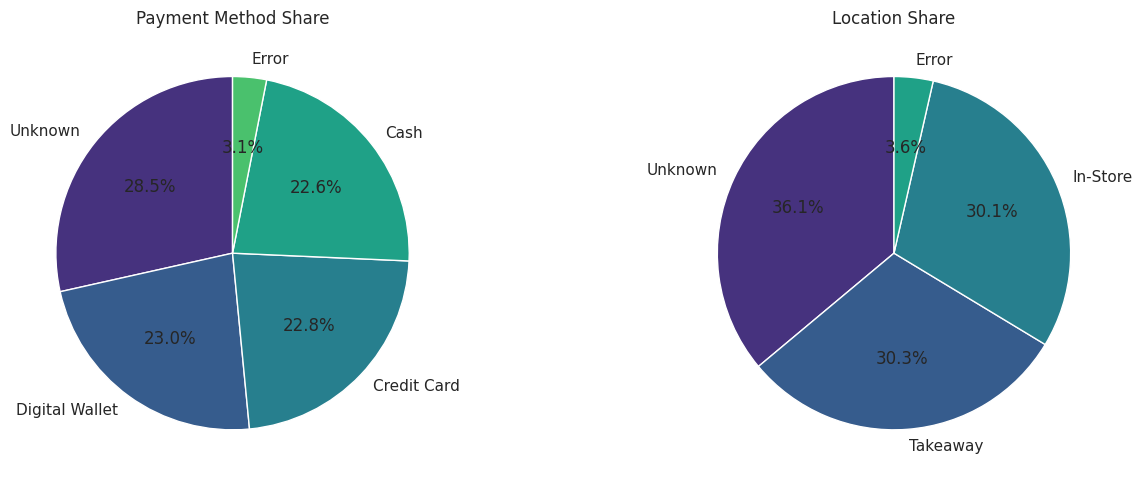

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pm = df["Payment Method"].value_counts()
ax[0].pie(pm.values, labels=pm.index, autopct="%1.1f%%", startangle=90)
ax[0].set_title("Payment Method Share")
loc = df["Location"].value_counts()
ax[1].pie(loc.values, labels=loc.index, autopct="%1.1f%%", startangle=90)
ax[1].set_title("Location Share")
save("04_payment_location_share")

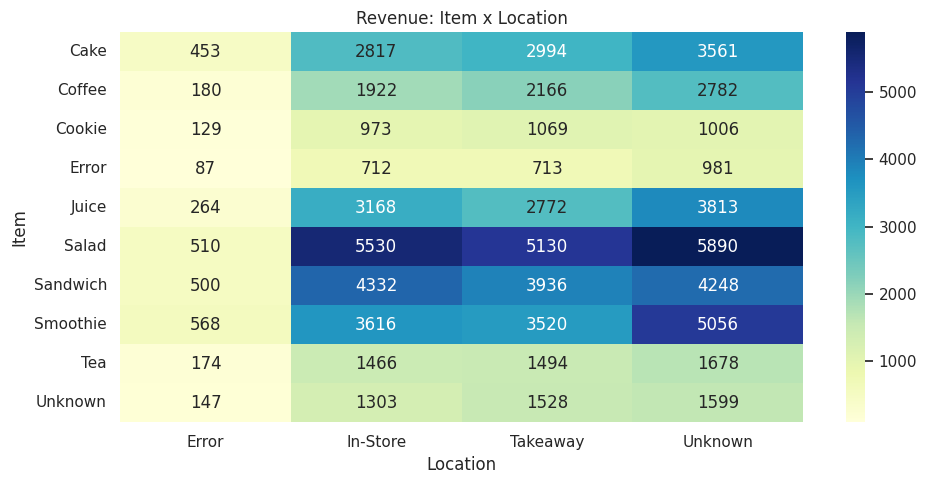

In [11]:
pivot = df.pivot_table(index="Item", columns="Location", values="Total Spent", aggfunc="sum")
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Revenue: Item x Location")
save("05_item_location_heatmap")

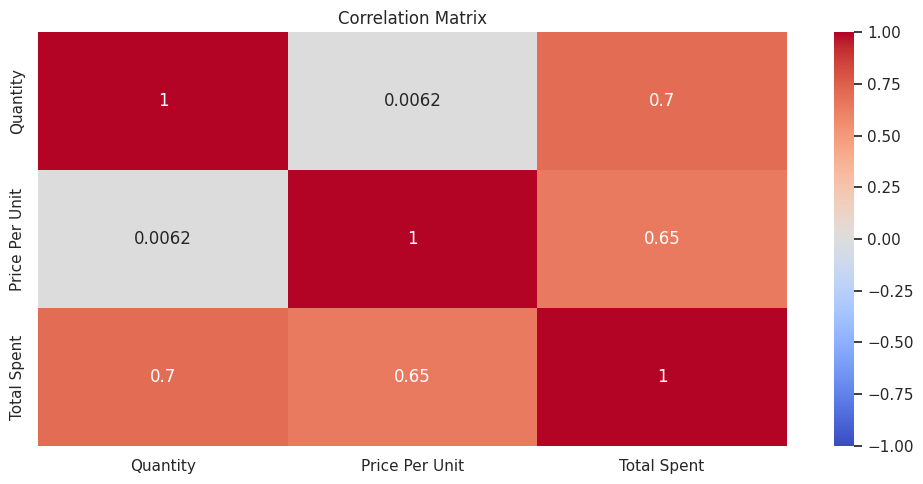

In [12]:
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
save("06_correlation")

IQR bounds: -8.00 to 24.00
Outliers: 259 (2.7%)
Item
Salad      243
Error        9
Unknown      7
Name: count, dtype: int64


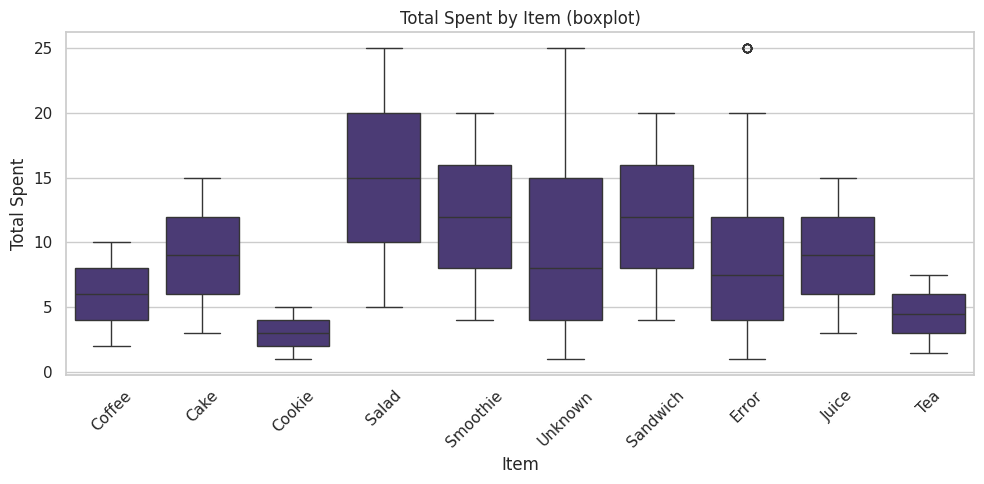

In [13]:
q1, q3 = df["Total Spent"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outliers = df[(df["Total Spent"] < low) | (df["Total Spent"] > high)]
print(f"IQR bounds: {low:.2f} to {high:.2f}")
print(f"Outliers: {len(outliers)} ({len(outliers) / len(df) * 100:.1f}%)")
print(outliers["Item"].value_counts())

sns.boxplot(data=df, x="Item", y="Total Spent")
plt.title("Total Spent by Item (boxplot)"); plt.xticks(rotation=45)
save("07_boxplot_item")

In [28]:
mismatch = df[(df["Quantity"] * df["Price Per Unit"] - df["Total Spent"]).abs() > 0.01]
print("Rows where Total Spent != Quantity x Price:", len(mismatch))
for col in ["Item", "Payment Method", "Location"]:
    n = (df[col].astype(str).str.lower() == "unknown").sum()
    print(f"'Unknown' in {col}: {n} ({n / len(df) * 100:.1f}%)")

Rows where Total Spent != Quantity x Price: 0
'Unknown' in Item: 491 (5.2%)
'Unknown' in Payment Method: 2708 (28.5%)
'Unknown' in Location: 3428 (36.1%)


Anomalous days: 0
Series([], Name: Total Spent, dtype: float64)


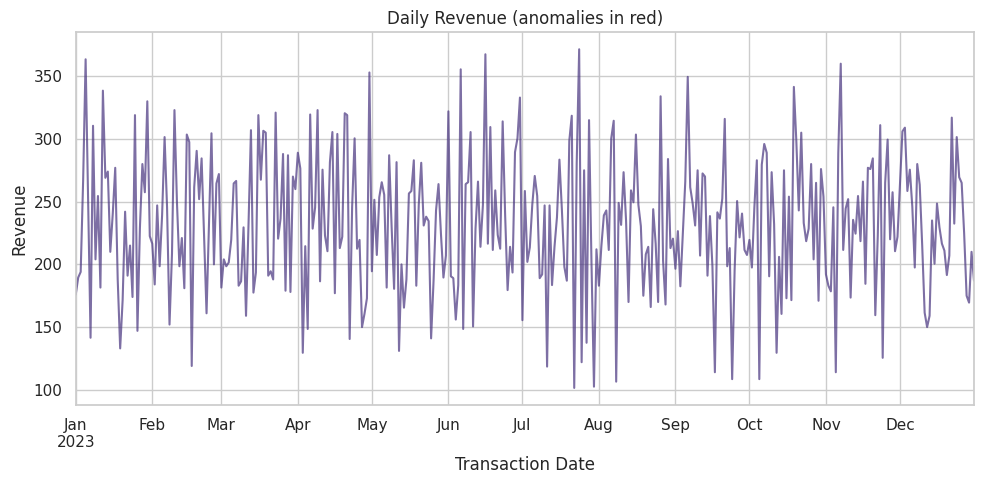

In [15]:
daily = df.groupby("Transaction Date")["Total Spent"].sum()
z = (daily - daily.mean()) / daily.std()
anom = daily[z.abs() > 3]
print(f"Anomalous days: {len(anom)}")
print(anom)

daily.plot(alpha=0.7, title="Daily Revenue (anomalies in red)")
if len(anom): plt.scatter(anom.index, anom.values, color="red", zorder=5)
plt.ylabel("Revenue")
save("08_daily_anomalies")

In [16]:
best_m, worst_m = monthly["Revenue"].idxmax(), monthly["Revenue"].idxmin()
top_item = item_stats.index[0]
top2_share = item_stats["Revenue Share %"].head(2).sum()
wk = df.groupby("Is Weekend")["Total Spent"].mean()
daily_df = df.groupby(["Transaction Date", "Is Weekend"])["Total Spent"].sum().reset_index()
wk_daily = daily_df.groupby("Is Weekend")["Total Spent"].mean()
unk_pay = (df["Payment Method"].str.lower() == "unknown").mean() * 100
unk_loc = (df["Location"].str.lower() == "unknown").mean() * 100
loc_rev = df.groupby("Location")["Total Spent"].sum()
loc_aov = df.groupby("Location")["Total Spent"].mean()
pay_rev = df.groupby("Payment Method")["Total Spent"].sum()

print(f"1. Best month: {best_m} ({monthly['Revenue'].max():,.0f}); weakest: {worst_m} ({monthly['Revenue'].min():,.0f})")
print(f"2. Top item: {top_item} ({item_stats['Revenue Share %'].iloc[0]}% of revenue); top 2 items = {top2_share:.1f}%")
print(f"   Most units: {item_stats['Units'].idxmax()}; highest price: {item_stats['Price'].idxmax()}")
print(f"3. Avg order value weekday vs weekend: {wk[False]:.2f} vs {wk[True]:.2f}")
print(f"   Avg daily revenue weekday vs weekend: {wk_daily[False]:.0f} vs {wk_daily[True]:.0f}")
print(f"4. Revenue by location:\n{loc_rev.round(0).to_string()}")
print(f"   Avg order value by location:\n{loc_aov.round(2).to_string()}")
print(f"5. Revenue by payment method:\n{pay_rev.round(0).to_string()}")
print(f"6. 'Unknown' payment: {unk_pay:.1f}%, 'Unknown' location: {unk_loc:.1f}%")
print(f"7. Skew of Total Spent = {df['Total Spent'].skew():.2f}; outliers = {len(outliers)}")

1. Best month: 2023-06 (7,350); weakest: 2023-02 (6,634)
2. Top item: Salad (20.1% of revenue); top 2 items = 35.5%
   Most units: Coffee; highest price: Salad
3. Avg order value weekday vs weekend: 8.93 vs 8.90
   Avg daily revenue weekday vs weekend: 233 vs 231
4. Revenue by location:
Location
Error        3012.0
In-Store    25838.0
Takeaway    25322.0
Unknown     30614.0
   Avg order value by location:
Location
Error       8.88
In-Store    9.04
Takeaway    8.80
Unknown     8.93
5. Revenue by payment method:
Payment Method
Cash              19495.0
Credit Card       19456.0
Digital Wallet    19512.0
Error              2544.0
Unknown           23778.0
6. 'Unknown' payment: 28.5%, 'Unknown' location: 36.1%
7. Skew of Total Spent = 0.83; outliers = 259
